# Case Study Data Exploration:

This data exploaration is divided in 2 parts:
1. The Highlights
2. Demographic and BMI breakdown
3. Statistical Analysis

### Libraries and Data Loading

### installing statsmodel

In [5]:
!pip install statsmodels

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, ttest_ind, mannwhitneyu
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest

In [7]:
hse_99 = pd.read_stata("HSE_1999.dta", convert_categoricals=False)
hse_19 = pd.read_stata("HSE_2019.dta", convert_categoricals=False)

## The Highlights (Diabete2, EverDi, Docinfo1, and Diabetes)

### Finding the column matches from 1999 and 2019 data

In [8]:
def find_col(df, target):
    matches = [c for c in df.columns if c.lower() == target.lower()]
    return matches[0] if matches else None

diab_cols_99 = find_col(hse_99, 'diabete2')
diab_cols_19 = find_col(hse_19, 'diabete2')

col_everdi_99 = find_col(hse_99, 'everdi')
col_everdi_19 = find_col(hse_19, 'everdi')

col_docinfo_99 = find_col(hse_99, 'diabetes')
col_docinfo_19 = find_col(hse_19, 'docinfo1')

### Diabete2 (Doctor-diagnosed diabetes excluding pregnant)

In [9]:
print("== 1. Diabete2 (Doctor-diagnosed diabtes excluding pregnant) ==")
print("\n1999 diabete2 value counts:", hse_99["diabete2"].value_counts(dropna=False))
print("\n2019 diabete2 value counts:", hse_19["diabete2"].value_counts(dropna=False))

== 1. Diabete2 (Doctor-diagnosed diabtes excluding pregnant) ==

1999 diabete2 value counts: diabete2
 2    9829
 1     429
-8       1
Name: count, dtype: int64

2019 diabete2 value counts: diabete2
 2.0    7566
-1.0    2095
 1.0     638
Name: count, dtype: int64


In [10]:
clean_diabete2_99 = hse_99[hse_99['diabete2'] > 0]
total_diabete2_99 = len(clean_diabete2_99)
diabete2_99 = (clean_diabete2_99['diabete2'] == 1).sum()
pct_diabete2_99 = (diabete2_99 / total_diabete2_99) * 100

clean_diabete2_19 = hse_19[hse_19['diabete2'] > 0]
total_diabete2_19 = len(clean_diabete2_19)
diabete2_19 = (clean_diabete2_19['diabete2'] == 1).sum()
pct_diabete2_19 = (diabete2_19 / total_diabete2_19) * 100

print(f"1999 Diagnosed Diabetes Prevalence: {pct_diabete2_99:.2f}% ({diabete2_99} out of {total_diabete2_99})")
print(f"2019 Diagnosed Diabetes Prevalence: {pct_diabete2_19:.2f}% ({diabete2_19} out of {total_diabete2_19})")


1999 Diagnosed Diabetes Prevalence: 4.18% (429 out of 10258)
2019 Diagnosed Diabetes Prevalence: 7.78% (638 out of 8204)


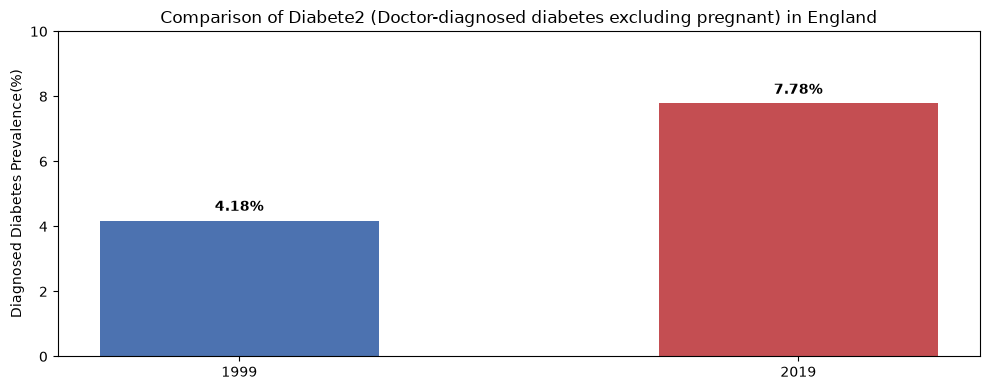

In [11]:
years = ["1999", "2019"]
prevalence = [4.18, 7.78]

plt.figure(figsize=(10, 4))
plt.bar(years, prevalence, color=["#4c72b0", "#c44e52"], width=0.5)
plt.ylabel("Diagnosed Diabetes Prevalence(%)")
plt.title("Comparison of Diabete2 (Doctor-diagnosed diabetes excluding pregnant) in England")
plt.ylim(0, 10)

for i, v, in enumerate(prevalence):
    plt.text(i, v + 0.3, f"{v}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("diabetes comparison.png", dpi=300)
plt.show()

### EverDi (ever had diabetes)

In [12]:
print("== 2. EVERDI (Ever had diabetes) ==")
if col_everdi_99:
    print(f"1999 ({col_everdi_99}): \n", hse_99[col_everdi_99].value_counts(dropna=False))
if col_everdi_19:
    print(f"\n2019 ({col_everdi_19}): \n", hse_19[col_everdi_19].value_counts(dropna=False))

== 2. EVERDI (Ever had diabetes) ==
1999 (everdi): 
 everdi
 2    6353
-1    3416
 1     482
-8       6
-9       2
Name: count, dtype: int64

2019 (EverDi): 
 EverDi
 2.0    7501
-1.0    2095
 1.0     696
-8.0       5
-9.0       2
Name: count, dtype: int64


In [13]:
clean_everdi_99 = hse_99[hse_99['everdi'] > 0]
total_everdi_99 = len(clean_everdi_99)
everdi_99 = (clean_everdi_99['everdi'] == 1).sum()
pct_everdi_99 = (everdi_99 / total_everdi_99) * 100

clean_everdi_19 = hse_19[hse_19['EverDi'] > 0]
total_everdi_19 = len(clean_everdi_19)
everdi_19 = (clean_everdi_19['EverDi'] == 1).sum()
pct_everdi_19 = (everdi_19 / total_everdi_19) * 100

print(f"1999 Diagnosed Diabetes Prevalence: {pct_everdi_99:.2f}% ({everdi_99} out of {total_everdi_99})")
print(f"2019 Diagnosed Diabetes Prevalence: {pct_everdi_19:.2f}% ({everdi_19} out of {total_everdi_19})")


1999 Diagnosed Diabetes Prevalence: 7.05% (482 out of 6835)
2019 Diagnosed Diabetes Prevalence: 8.49% (696 out of 8197)


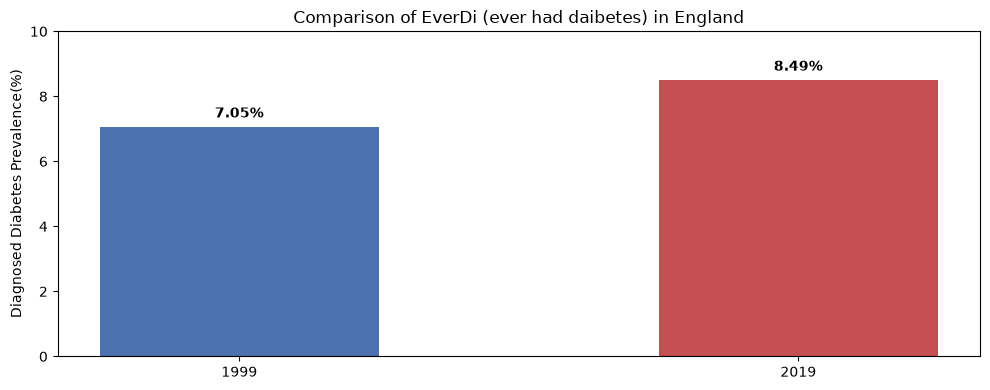

In [14]:
years = ["1999", "2019"]
prevalence = [7.05, 8.49]

plt.figure(figsize=(10, 4))
plt.bar(years, prevalence, color=["#4c72b0", "#c44e52"], width=0.5)
plt.ylabel("Diagnosed Diabetes Prevalence(%)")
plt.title("Comparison of EverDi (ever had daibetes) in England")
plt.ylim(0, 10)

for i, v, in enumerate(prevalence):
    plt.text(i, v + 0.3, f"{v}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("diabetes comparison.png", dpi=300)
plt.show()

### Diabetes (1999) and DOCINFO1 (2019) - Both doctor diagnosed diabetes or told by a doctor had diabetes

In [15]:
print("== 3. Doctor Diagnosed Comparison (DOCINFO1 & Diabetes) ==")
if col_docinfo_99:
    print(f"1999 ({col_docinfo_99}): \n", hse_99[col_docinfo_99].value_counts(dropna=False))
if col_docinfo_19:
    print(f"\n2019 ({col_docinfo_19}): \n", hse_19[col_docinfo_19].value_counts(dropna=False))

== 3. Doctor Diagnosed Comparison (DOCINFO1 & Diabetes) ==


The are no data for Diabetes and DOCINFO1. These variables are present in their respective dictionaries but are absent in the dataset.

In [16]:
print("1999 columns matching 'diab:", [c for c in hse_99.columns if 'diab' in c.lower()])
print("\n2019 columns matching 'doc:", [c for c in hse_19.columns if 'doc' in c.lower()])

1999 columns matching 'diab: ['diabete2']

2019 columns matching 'doc: ['DocBP', 'DocGroup', 'DocSeenY', 'DocTalkG', 'DocTalkG4', 'DocTalkYr', 'DocWhyYr']


## Demographic and BMI Breakdown

### Diabetes Prevalence by Age Group

In [17]:
print("1999 Age Columns",[c for c in hse_99.columns if 'ag' in c.lower()])
print("2019 Age Columns", [c for c in hse_19.columns if 'ag' in c.lower()])

1999 Age Columns ['age', 'irndage', 'nrndage', 'agebook', 'ag16g20', 'ag16g10', 'ag215g2', 'ag215g3', 'ag415g3', 'ag515g3', 'ag715g3', 'ag1324g4', 'ag1624g2', 'ag1624g4', 'ageangi', 'ageinfbp', 'ageheart', 'agestro', 'ageinfo1', 'ageinmur', 'ageireg', 'ageoht', 'ddrinkag', 'adrinkag', 'cdrinage', 'hrtageg5', 'hrtage', 'dcigage', 'kcigage']
2019 Age Columns ['ADrinkAg', 'Ag015g4', 'ag16g10', 'age16g5', 'Age35g', 'AgeBPg', 'Agehlp2G5', 'Agehlp3G5', 'AgehlpG5', 'DiAgeG', 'fath_age16g5R', 'HRPpayagR', 'iffcvalag4', 'KCigAge', 'moth_age16g5R', 'PayAgeR']


In [18]:
print("1999 Diabetes Prevalence by Age Group:")
print(clean_diabete2_99.groupby('ag16g10', observed=False)['diabete2'].apply(lambda x: f"{((x==1).sum() / len(x)) * 100:.2f}% (n = {(x==1).sum()} / {len(x)})"))

print("\n2019 Diabetes Prevalence by Age Group:")
print(clean_diabete2_19.groupby('ag16g10', observed=False)['diabete2'].apply(lambda x: f"{((x==1).sum() / len(x)) * 100:.2f}% (n = {(x==1).sum()} / {len(x)})"))

1999 Diabetes Prevalence by Age Group:
ag16g10
-1      0.00% (n = 0 / 3415)
 1      0.30% (n = 4 / 1326)
 2     1.21% (n = 19 / 1568)
 3     3.07% (n = 48 / 1564)
 4      8.61% (n = 84 / 976)
 5    16.71% (n = 121 / 724)
 6    23.62% (n = 120 / 508)
 7     18.64% (n = 33 / 177)
Name: diabete2, dtype: str

2019 Diabetes Prevalence by Age Group:
ag16g10
1.0        0.69% (n = 5 / 729)
2.0      1.11% (n = 12 / 1083)
3.0      2.65% (n = 37 / 1397)
4.0      5.51% (n = 78 / 1416)
5.0    10.97% (n = 148 / 1349)
6.0    15.70% (n = 195 / 1242)
7.0     16.50% (n = 163 / 988)
Name: diabete2, dtype: str


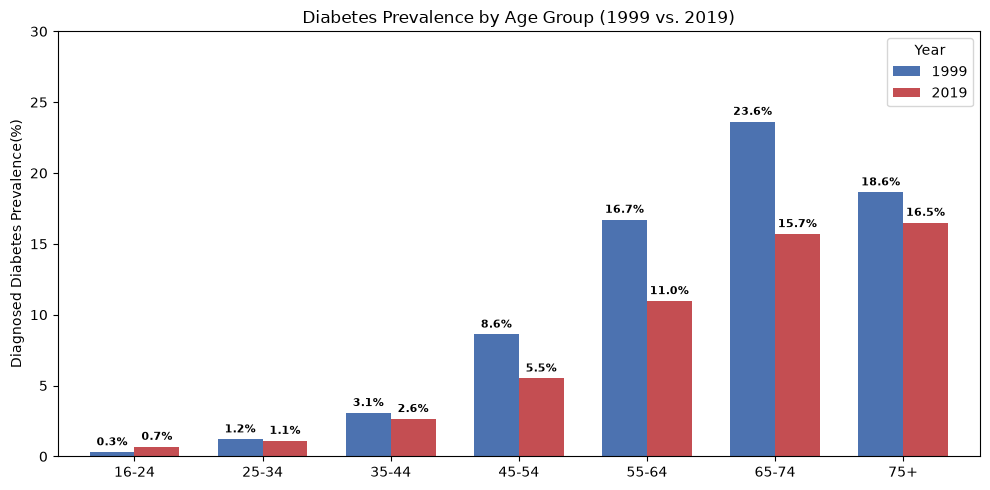

In [19]:
p99_age = clean_diabete2_99[clean_diabete2_99['ag16g10'] > 0].groupby('ag16g10')['diabete2'].apply(lambda x: ((x==1).sum() / len(x)) * 100)
p19_age = clean_diabete2_19[clean_diabete2_19['ag16g10'] > 0].groupby('ag16g10')['diabete2'].apply(lambda x: ((x==1).sum() / len(x)) * 100)

age_df = pd.DataFrame({'1999': p99_age, '2019':p19_age})
age_df.index = ['16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75+']


fig, ax = plt.subplots(figsize=(10, 5))
age_df.plot(kind='bar', ax=ax, color=['#4c72b0', '#c44e52'], width=0.7)

ax.set_ylabel('Diagnosed Diabetes Prevalence(%)')
ax.set_title('Diabetes Prevalence by Age Group (1999 vs. 2019)')
ax.set_xticklabels(age_df.index, rotation=0)
ax.set_ylim(0, 30)
ax.legend(title='Year')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig("diabetes_by_age.png", dpi=300)
plt.show()

### Diabetes Prevalence by Gender in 1999 and 2019

In [20]:
print("1999 Diabetes Prevalence by Gender (Male: 1 & Female: 2)")
gender_99 = hse_99[hse_99['diabete2'] > 0]
print(gender_99.groupby('sex')['diabete2'].apply(lambda x: f"{( (x == 1).sum() / len(x) ) * 100:.2f}% (n = {(x == 1).sum()} / {len(x)})"))

print("\n1999 Diabetes Prevalence by Gender (Male: 1 & Female: 2)")
gender_19 = hse_19[hse_19['diabete2'] > 0]
print(gender_19.groupby('Sex')['diabete2'].apply(lambda x: f"{( (x == 1).sum() / len(x) ) * 100:.2f}% (n = {(x == 1).sum()} / {len(x)})"))

1999 Diabetes Prevalence by Gender (Male: 1 & Female: 2)
sex
1    4.94% (n = 243 / 4922)
2    3.49% (n = 186 / 5336)
Name: diabete2, dtype: str

1999 Diabetes Prevalence by Gender (Male: 1 & Female: 2)
Sex
1.0    9.80% (n = 360 / 3674)
2.0    6.14% (n = 278 / 4530)
Name: diabete2, dtype: str


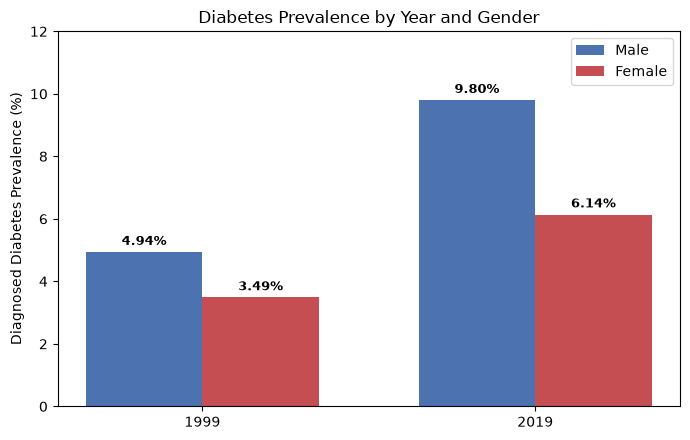

In [21]:
p99_gender = gender_99.groupby('sex')['diabete2'].apply(lambda x: ((x==1).sum() / len(x)) * 100)
p19_gender = gender_19.groupby('Sex')['diabete2'].apply(lambda x: ((x==1).sum() / len(x)) * 100)

male_vals = [p99_gender.loc[1.0], p19_gender.loc[1.0]]
female_vals = [p99_gender.loc[2.0], p19_gender.loc[2.0]]

labels_years = ['1999', '2019']
x = list(range(len(labels_years)))
width = 0.35

fig, ax = plt.subplots(figsize=(7,4.5))
ax.bar([i - width/2 for i in x], male_vals, width, label='Male', color='#4c72b0')
ax.bar([i + width/2 for i in x], female_vals, width, label='Female', color='#c44e52')

ax.set_ylabel('Diagnosed Diabetes Prevalence (%)')
ax.set_title('Diabetes Prevalence by Year and Gender')
ax.set_xticks(x)
ax.set_xticklabels(labels_years)
ax.set_ylim(0, 12)
ax.legend()

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f%%', padding=3, fontweight='bold',fontsize=9)

plt.tight_layout()
plt.savefig("diabetes_by_gender.png", dpi=300)
plt.show()

### Diabetes Prevalence by BMI Groups in 1999 and 2019

In [22]:
bmi_bins = [0, 18.5, 25, 30, 100]
bmi_labels = ['Underweight (< 18.5)', 'Normal (18.5-24.9)', 'Overweight (25-29.9)', 'Obese (30+)']

clean_diabete2_99['bmi_group'] =pd.cut(clean_diabete2_99['bmi'], bins=bmi_bins, labels=bmi_labels)
clean_diabete2_19['bmi_group'] =pd.cut(clean_diabete2_19['BMI'], bins=bmi_bins, labels=bmi_labels)

print("1999 Prevalence by BMI group:")
print(clean_diabete2_99.groupby('bmi_group', observed=False)['diabete2'].apply(lambda x: f"{((x==1).sum() / len(x)) * 100:.2f}% (n = {(x==1).sum()} / {len(x)})"))
print("\n2019 Prevalence by BMI group:")
print(clean_diabete2_19.groupby('bmi_group', observed=False)['diabete2'].apply(lambda x: f"{((x==1).sum() / len(x)) * 100:.2f}% (n = {(x==1).sum()} / {len(x)})"))

1999 Prevalence by BMI group:
bmi_group
Underweight (< 18.5)      0.05% (n = 1 / 2120)
Normal (18.5-24.9)      3.07% (n = 105 / 3418)
Overweight (25-29.9)    6.45% (n = 143 / 2216)
Obese (30+)             9.70% (n = 102 / 1052)
Name: diabete2, dtype: str

2019 Prevalence by BMI group:
bmi_group
Underweight (< 18.5)        0.00% (n = 0 / 100)
Normal (18.5-24.9)        2.92% (n = 63 / 2157)
Overweight (25-29.9)     7.93% (n = 197 / 2485)
Obese (30+)             11.95% (n = 242 / 2025)
Name: diabete2, dtype: str


C:\Users\Admin\AppData\Local\Temp\ipykernel_4260\1006963768.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  clean_diabete2_99['bmi_group'] =pd.cut(clean_diabete2_99['bmi'], bins=bmi_bins, labels=bmi_labels)


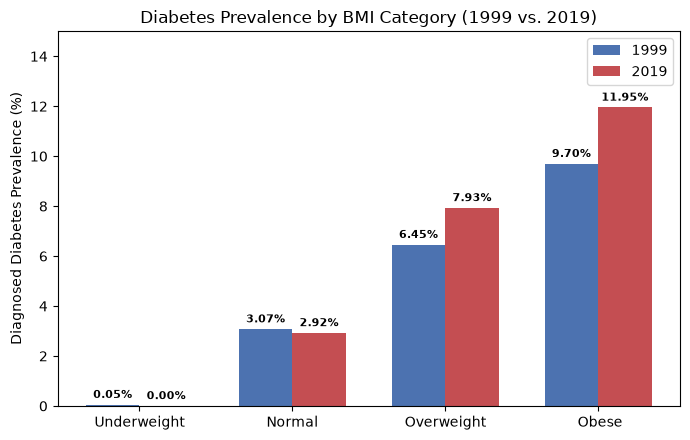

In [28]:
p99_bmi = clean_diabete2_99.groupby('bmi_group', observed=False)['diabete2'].apply(lambda x: ((x==1).sum() / len(x)) * 100)
p19_bmi = clean_diabete2_19.groupby('bmi_group', observed=False)['diabete2'].apply(lambda x: ((x==1).sum() / len(x)) * 100)

labels_bmi = ['Underweight', 'Normal', 'Overweight', ' Obese']
x = list(range(len(labels_bmi)))
width = 0.35

fig, ax = plt.subplots(figsize=(7,4.5))
ax.bar([i - width/2 for i in x], p99_bmi, width, label='1999', color='#4c72b0')
ax.bar([i + width/2 for i in x], p19_bmi, width, label='2019', color='#c44e52')

ax.set_ylabel('Diagnosed Diabetes Prevalence (%)')
ax.set_title('Diabetes Prevalence by BMI Category (1999 vs. 2019)')
ax.set_xticks(x)
ax.set_xticklabels(labels_bmi)
ax.set_ylim(0, 15)
ax.legend()

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f%%', padding=3, fontweight='bold',fontsize=8)

plt.tight_layout()
plt.savefig("diabetes_by_bmi.png", dpi=300)
plt.show()

## Statistical Analysis

### Chi-Square Test of Independence (age group vs diabetes)

For this, we are testing whether there is a significant association between two categorical variables ( e.g., whether diagnosed diabetes proportions differ significantly between males and females).

In [24]:
df_valid = clean_diabete2_19[clean_diabete2_19['ag16g10'] > 0]

contingency_table = pd.crosstab(df_valid['ag16g10'], df_valid['diabete2'])

chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value:{p_val:.4e}")
print(f"Degrees of Freedom: {dof}")

Chi-Square Statistic: 412.3492
P-value:6.1826e-86
Degrees of Freedom: 6


Result interpretation:

There is extremely significant association between age group and diagnosed diabetes status. Diabetes diagnosisis not unifromly distributed across age groups, that is older age brackets carry a disproportionately higher prevalence.

### BMI Comparison (diabetic vs. non-diabetic)

For this, we are testing whether the mean BMIof individuals with diabetes is significantly different from the mena BMI of those without diabetes. 

The Mann_Whitney U test is used when the BMI data is heavily skewed

In [25]:
bmi_diabetic = clean_diabete2_19[clean_diabete2_19['diabete2'] == 1]['BMI'].dropna()
bmi_nondiabetic = clean_diabete2_19[clean_diabete2_19['diabete2'] == 2]['BMI'].dropna()

t_stat, t_pval = ttest_ind(bmi_diabetic, bmi_nondiabetic, equal_var=False)
print(f"Welch's t-test: t-stat = {t_stat:.4f}, P-value = {t_pval:.4e}")

u_stat, u_pval =mannwhitneyu(bmi_diabetic, bmi_nondiabetic, alternative='two-sided')
print(f"Mann-Whitney U test: U-stat = {u_stat:.4f}, P-value = {u_pval:.4e}")

Welch's t-test: t-stat = 2.7856, P-value = 5.4838e-03
Mann-Whitney U test: U-stat = 2857461.0000, P-value = 9.3616e-15


Result interpretation:

Individuals with diagnosed diabetes have a statistically significantly higher mean and median BMI than non-diabetics. The ultra-low p-value from th non-parametric Mann-Whitney U test confirms that this result remans robust even after accounting for skewness in the BMI distribution.

### Logistic Regression Model

For this, we are testing the odds of having diabetes given a person's BMI, age, and gender, controlling for confounding variables.

In [26]:
model_df = clean_diabete2_19.copy()

model_df['diabetes_bin'] = (model_df['diabete2'] == 1).astype(int)

logit_model = smf.logit(
    "diabetes_bin ~ag16g10 + BMI + C(Sex)",
    data=model_df
).fit()

print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.245477
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:           diabetes_bin   No. Observations:                 8204
Model:                          Logit   Df Residuals:                     8200
Method:                           MLE   Df Model:                            3
Date:                Thu, 29 Oct 2026   Pseudo R-squ.:                  0.1017
Time:                        00:13:00   Log-Likelihood:                -2013.9
converged:                       True   LL-Null:                       -2242.0
Covariance Type:            nonrobust   LLR p-value:                 1.471e-98
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -4.9749      0.188    -26.429      0.000      -5.344      -4.606
C(Sex)[T.2.0]    -0.

Result interpretation:

Females have significantly lower odds of diagnosed diabetes compared to males (reference group). Specifically, females exhibit roughly 38% lower odds (~ 1 - 0.62) of having diagnosed diabetes when controllin for age and BMI.

### To Answer the Research Question: Has the number of people with diagnosed diabetes increased in the last 20 years in England?

To answer our research question, we use two-proportion z-test because it directly compares proportions between two independent groups (1999 vs 2019) and allows for one-tailed directional test (prevalence2019 > prevalence1999), which precisely matches our hypothesis that diagnosed diabetes increased

In [27]:
df_99 = clean_diabete2_99[clean_diabete2_99['ag16g10'] >0 ]
df_19 = clean_diabete2_19[clean_diabete2_19['ag16g10'] >0 ]

count_19 = (df_19['diabete2'] == 1).sum()
nobs_19 = len(df_19['diabete2'].dropna())

count_99 = (df_99['diabete2'] == 1).sum()
nobs_99 = len(df_99['diabete2'].dropna())

successes = np.array([count_19, count_99])
samples = np.array([ nobs_19, nobs_99])

z_stat, p_val = proportions_ztest(successes, samples, alternative='larger')

print(f"2019 Prevalence: {(count_19 / nobs_19) * 100:.2f}%  (n = {nobs_19})")
print(f"1999 Prevalence: {(count_99 / nobs_99) * 100:.2f}%  (n = {nobs_99})")
print("-" * 40)
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_val:.4e}")

2019 Prevalence: 7.78%  (n = 8204)
1999 Prevalence: 6.27%  (n = 6843)
----------------------------------------
Z-statistic: 3.5875
P-value: 1.6696e-04


Finding: 

A one-tailed two-proportion Z-test reveeals a statistically significant increase in the prevalence of diagnosed diabetes in England between 1999 (6.27%) and 2019 (7.78%), Z = 3.59, p < 0.001.

Conclusion:

We reject the null hypothesis that diagnosed dieabetes has not increased over the 20-year period. The data provides strong emperical evidence supporting the alternative hypothesis that diagnosed diabetes prevalence significantly increased in England from 1999 to 2019.